# Data Analysis — Predicting Next File Arrival Time

This notebook performs the exploratory data analysis phase of the project,
using the raw datasets produced by `data_pipeline.py`, which has schema as:

| column | meaning |
|---|---|
| `source_id` | which source/flight this arrival belongs to |
| `pattern_description` | human-readable description of the source |
| `arrival_timestamp` | when the file/flight actually arrived |

**Contents**
1. Load and inspect the synthetic dataset (26 sources)
2. Inter-arrival time distributions per source (histograms + ACF plots)
3. Per-source summary statistics (mean, median, std, skewness, and more)
4. Load and inspect the BTS airline dataset
5. Missing-data / logging-gap patterns in both datasets
6. Consolidated, report-ready summary tables


In [20]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100

# ── Configuration — adjust these paths to match your local layout ────────
SYNTHETIC_COMBINED_PATH = Path("../data/synthetic_arrivals.csv")
BTS_DATA_DIR            = Path("../data/bts")          # expects one .parquet per route
ANALYSIS_OUTPUT_DIR     = Path("../data/analysis_outputs")
ANALYSIS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# A gap counts as "long" (a likely logging/outage gap) if it exceeds this
# multiple of the source's own median gap. Relative, not a fixed number of
# hours, since sources range from hourly to annual cadence.
LONG_GAP_MULTIPLIER = 3.0

# A gap counts as part of a "burst" if it is shorter than this fraction of
# the source's own median gap.
BURST_RELATIVE_THRESHOLD = 0.5


In [17]:
import dataframe_image as dfi

## 1. Synthetic Dataset — Load & Overview

In [2]:

synth = pd.read_csv(SYNTHETIC_COMBINED_PATH, parse_dates=["arrival_timestamp"])
synth = synth.sort_values(["source_id", "arrival_timestamp"]).reset_index(drop=True)

synth["inter_arrival_hrs"] = (
    synth.groupby("source_id")["arrival_timestamp"]
    .diff().dt.total_seconds().div(3600)
)

print(f"Rows: {len(synth):,}   Columns: {synth.shape[1]}")
print(f"Date range: {synth['arrival_timestamp'].min()}  ->  {synth['arrival_timestamp'].max()}")
print(f"Sources: {synth['source_id'].nunique()}")
synth.head(3)


Rows: 34,389   Columns: 4
Date range: 2022-12-31 23:58:15.586431  ->  2024-12-31 22:57:56.917789
Sources: 26


,source_id,pattern_description,arrival_timestamp,inter_arrival_hrs
0,SRC_01,Daily at ~09:00 UTC — every calendar day,2023-01-01 09:13:25.354199,NaN
1,SRC_01,Daily at ~09:00 UTC — every calendar day,2023-01-02 09:21:05.042785,24.127691
2,SRC_01,Daily at ~09:00 UTC — every calendar day,2023-01-03 09:02:50.171727,23.695869


In [3]:

source_catalog = (
    synth[["source_id", "pattern_description"]]
    .drop_duplicates()
    .sort_values("source_id")
    .reset_index(drop=True)
)
source_catalog


,source_id,pattern_description
0,SRC_01,Daily at ~09:00 UTC — every calendar day
1,SRC_02,"Daily at ~09:00 UTC, ~4h late on Wednesdays"
2,SRC_03,Weekdays only at ~14:00 UTC
3,SRC_04,Monthly — first business day at ~06:00 UTC
4,SRC_05,Quarterly — first biz day of Jan/Apr/Jul/Oct a...
5,SRC_06,"Tuesday, Wednesday, Thursday only at ~11:00 UTC"
6,SRC_07,Weekdays excluding US federal holidays at ~08:...
7,SRC_08,Hourly 24/7
8,SRC_09,"Every 6 hours (00/06/12/18 UTC), every day"
9,SRC_10,Twice daily on weekdays (~08:00 and ~18:00 UTC)


## 2. Inter-Arrival Time Distributions per Source

Histograms confirm that sources genuinely differ in cadence and shape
(e.g. a tight peak near 24h for daily sources vs. a long right tail for
the heavy-tailed / bursty sources). ACF-style plots (on the *sequence* of
gaps, not calendar time) reveal whether a source's gaps are independent
from one arrival to the next (flat ACF) or show structure (e.g. a
self-exciting source showing short-lag correlation).

In [4]:

def plot_source_grid(source_ids, plot_fn, ncols=5, figsize_per_cell=(3.6, 2.6), **kwargs):
    # Small-multiples grid: calls plot_fn(ax, source_id, **kwargs) for each source.
    nrows = int(np.ceil(len(source_ids) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
    )
    axes = np.atleast_1d(axes).ravel()
    for ax, source_id in zip(axes, source_ids):
        plot_fn(ax, source_id, **kwargs)
    for ax in axes[len(source_ids):]:
        ax.axis("off")
    fig.tight_layout()
    return fig


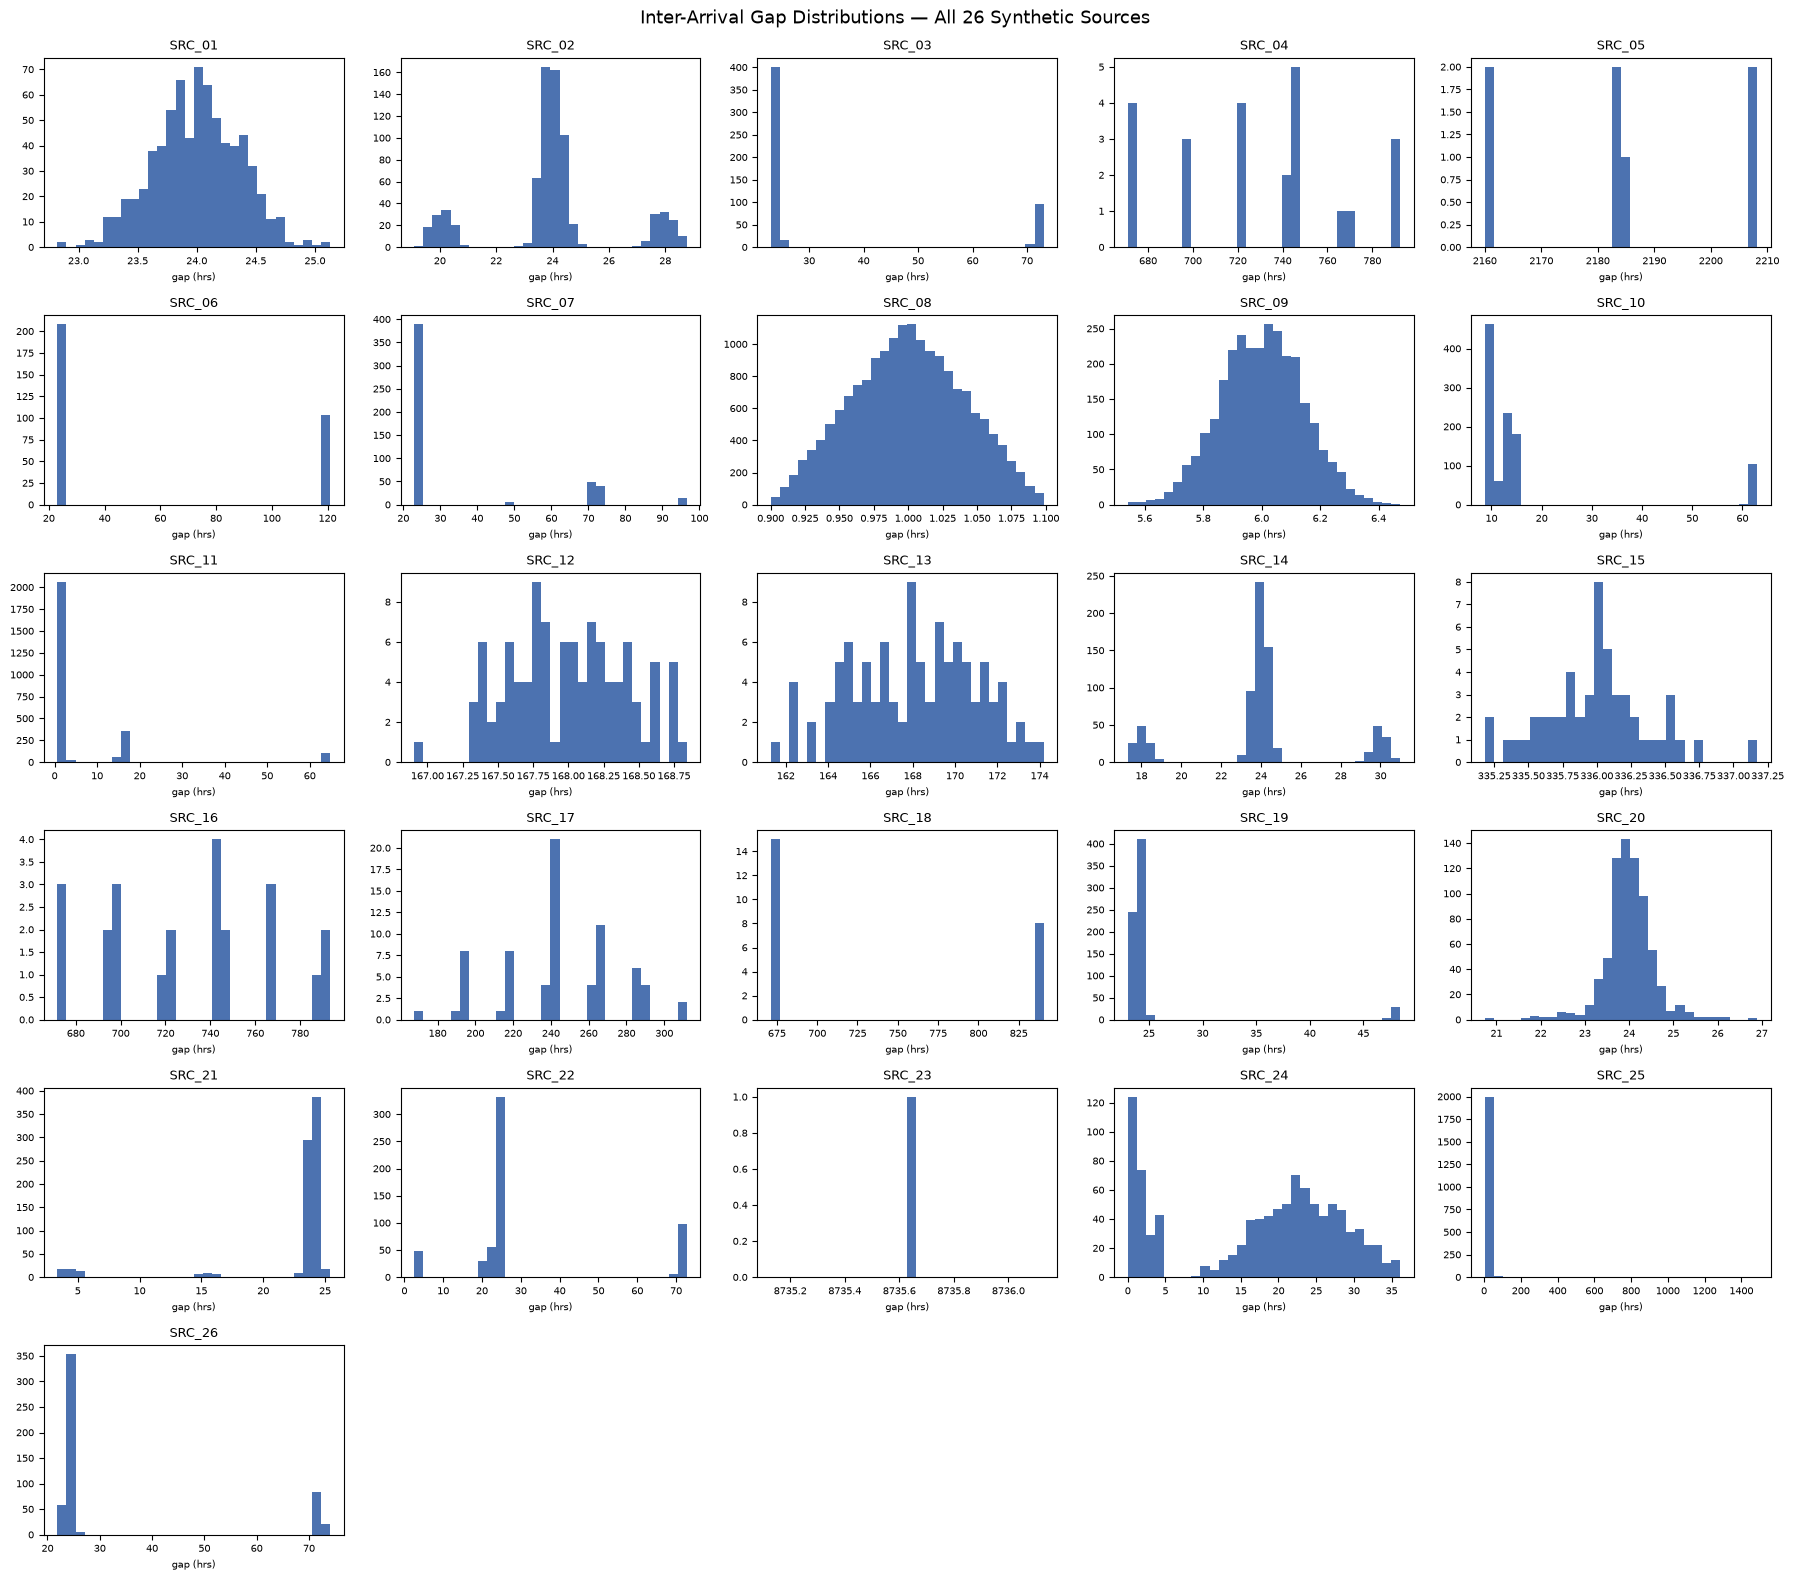

In [5]:

def _hist_panel(ax, source_id, df):
    gaps = df.loc[df["source_id"] == source_id, "inter_arrival_hrs"].dropna()
    if gaps.empty:
        ax.set_title(f"{source_id} (no gaps)")
        ax.axis("off")
        return
    ax.hist(gaps, bins=30, color="#4C72B0")
    ax.set_title(source_id, fontsize=9)
    ax.set_xlabel("gap (hrs)", fontsize=7)
    ax.tick_params(labelsize=7)

synthetic_sources = sorted(synth["source_id"].unique())
fig = plot_source_grid(synthetic_sources, _hist_panel, ncols=5, df=synth)
fig.suptitle("Inter-Arrival Gap Distributions — All 26 Synthetic Sources", y=1.01, fontsize=13)
plt.show()


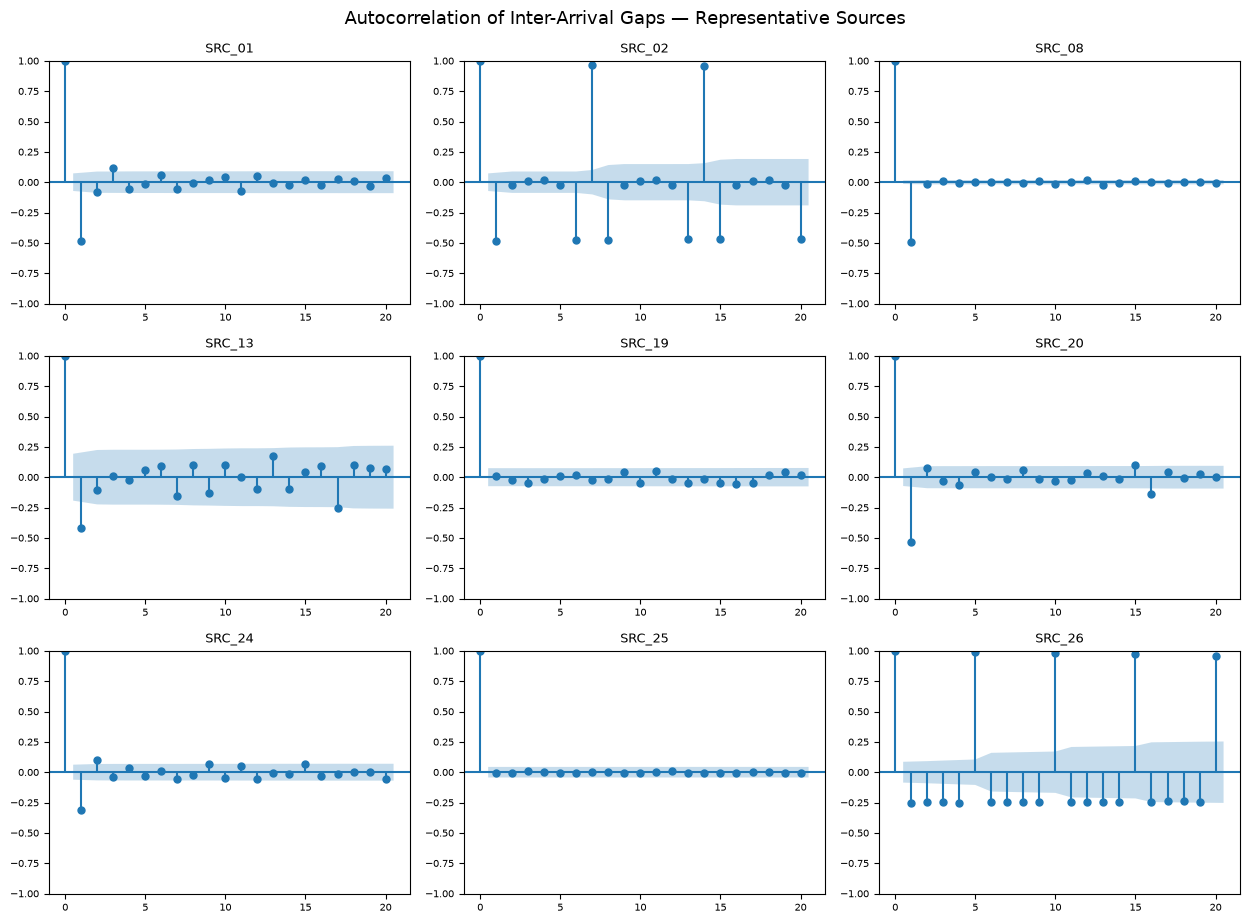

In [6]:

# A representative subset spanning the different pattern families, for the
# ACF view (very sparse sources like monthly/quarterly/annual don't have
# enough points for a meaningful autocorrelation plot).
acf_sources = ["SRC_01", "SRC_02", "SRC_08", "SRC_13", "SRC_19", "SRC_20", "SRC_24", "SRC_25", "SRC_26"]

def _acf_panel(ax, source_id, df, lags=20):
    gaps = df.loc[df["source_id"] == source_id, "inter_arrival_hrs"].dropna()
    if len(gaps) <= lags:
        ax.set_title(f"{source_id} (too short)")
        ax.axis("off")
        return
    plot_acf(gaps, ax=ax, lags=lags, title=source_id)
    ax.tick_params(labelsize=7)
    ax.title.set_size(9)

fig = plot_source_grid(acf_sources, _acf_panel, ncols=3, figsize_per_cell=(4.2, 3.0), df=synth)
fig.suptitle("Autocorrelation of Inter-Arrival Gaps — Representative Sources", y=1.02, fontsize=13)
plt.show()


## 3. Per-Source Summary Statistics
- **General statistics**: Mean, median, standard deviation, and the Pearsonian
(second) coefficient of skewness, `3(mean - median) / std`
- **Sequence length**: total number of arrivals observed for the source
- **Burst rate**: the fraction of a source's gaps that are "short"
  relative to its own typical gap, a simple proxy for clustered/bursty
  arrivals

In [7]:

def pearson_skewness(s: pd.Series) -> float:
    s = s.dropna()
    if len(s) <= 1 or s.std() == 0:
        return np.nan
    return 3 * (s.mean() - s.median()) / s.std()


def source_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Generic per-source summary — works for any dataframe with
    source_id, pattern_description, and inter_arrival_hrs columns."""
    rows = []
    for source_id, g in df.groupby("source_id"):
        gaps = g["inter_arrival_hrs"].dropna()
        row = {
            "source_id": source_id,
            "pattern": g["pattern_description"].iloc[0],
            "n_arrivals": len(g),
            "n_gaps": len(gaps),
            "mean_hrs": gaps.mean(),
            "median_hrs": gaps.median(),
            "std_hrs": gaps.std(),
            "var_hrs": gaps.var(),
            "min_hrs": gaps.min() if not gaps.empty else np.nan,
            "max_hrs": gaps.max() if not gaps.empty else np.nan,
            "pearson_skewness": pearson_skewness(gaps),
        }
        if not gaps.empty and gaps.median() > 0:
            row["burst_rate"] = (gaps < BURST_RELATIVE_THRESHOLD * gaps.median()).mean()
        else:
            row["burst_rate"] = np.nan
        rows.append(row)

    return pd.DataFrame(rows).sort_values("source_id").reset_index(drop=True)


synth_summary = source_summary(synth)
synth_summary.round(4)


,source_id,pattern,n_arrivals,n_gaps,mean_hrs,median_hrs,std_hrs,var_hrs,min_hrs,max_hrs,pearson_skewness,burst_rate
0,SRC_01,Daily at ~09:00 UTC — every calendar day,731,730,23.9999,24.0061,0.3649,0.1331,22.8211,25.1281,-0.0507,0.0000
1,SRC_02,"Daily at ~09:00 UTC, ~4h late on Wednesdays",731,730,24.0003,23.9786,2.1372,4.5675,19.0893,28.7681,0.0305,0.0000
2,SRC_03,Weekdays only at ~14:00 UTC,522,521,33.5818,24.1145,19.1963,368.4981,23.0041,73.0515,1.4795,0.0000
3,SRC_04,Monthly — first business day at ~06:00 UTC,24,23,729.3945,742.9827,38.8097,1506.1930,670.9524,792.5668,-1.0504,0.0000
4,SRC_05,Quarterly — first biz day of Jan/Apr/Jul/Oct a...,8,7,2184.0083,2183.9528,19.4162,376.9905,2159.9604,2208.2186,0.0086,0.0000
5,SRC_06,"Tuesday, Wednesday, Thursday only at ~11:00 UTC",313,312,56.0002,24.1873,45.3784,2059.1982,23.0706,120.9119,2.1032,0.0000
6,SRC_07,Weekdays excluding US federal holidays at ~08:...,500,499,35.0137,24.1063,21.3049,453.8990,22.9480,96.6155,1.5359,0.0000
7,SRC_08,Hourly 24/7,17544,17543,1.0000,0.9998,0.0408,0.0017,0.9002,1.0984,0.0118,0.0000
8,SRC_09,"Every 6 hours (00/06/12/18 UTC), every day",2924,2923,6.0000,6.0031,0.1400,0.0196,5.5421,6.4749,-0.0682,0.0000
9,SRC_10,Twice daily on weekdays (~08:00 and ~18:00 UTC),1044,1043,16.7848,11.1956,15.1699,230.1268,8.6234,62.9561,1.1053,0.0000


In [19]:

display_cols = [
    "source_id", "pattern", "n_arrivals", "mean_hrs", "median_hrs",
    "std_hrs", "pearson_skewness", "burst_rate",
]
df_styled = ((((synth_summary[display_cols].style).format({
    "mean_hrs": "{:.2f}", "median_hrs": "{:.2f}", "std_hrs": "{:.2f}",
    "pearson_skewness": "{:.3f}", "burst_rate": "{:.2%}",
}).background_gradient(subset=["pearson_skewness"], cmap="RdBu_r", vmin=-1, vmax=1))
                   .background_gradient(subset=["burst_rate"], cmap="Oranges"))
                   .set_caption("Per-Source Summary Statistics — Synthetic Dataset"))
dfi.export(df_styled, 'synth_summary_styled_table.png', table_conversion='matplotlib')
df_styled

,source_id,pattern,n_arrivals,mean_hrs,median_hrs,std_hrs,pearson_skewness,burst_rate
0,SRC_01,Daily at ~09:00 UTC — every calendar day,731,24.00,24.01,0.36,-0.051,0.00%
1,SRC_02,"Daily at ~09:00 UTC, ~4h late on Wednesdays",731,24.00,23.98,2.14,0.030,0.00%
2,SRC_03,Weekdays only at ~14:00 UTC,522,33.58,24.11,19.20,1.480,0.00%
3,SRC_04,Monthly — first business day at ~06:00 UTC,24,729.39,742.98,38.81,-1.050,0.00%
4,SRC_05,Quarterly — first biz day of Jan/Apr/Jul/Oct at ~06:00 UTC,8,2184.01,2183.95,19.42,0.009,0.00%
5,SRC_06,"Tuesday, Wednesday, Thursday only at ~11:00 UTC",313,56.00,24.19,45.38,2.103,0.00%
6,SRC_07,Weekdays excluding US federal holidays at ~08:00 UTC,500,35.01,24.11,21.30,1.536,0.00%
7,SRC_08,Hourly 24/7,17544,1.00,1.00,0.04,0.012,0.00%
8,SRC_09,"Every 6 hours (00/06/12/18 UTC), every day",2924,6.00,6.00,0.14,-0.068,0.00%
9,SRC_10,Twice daily on weekdays (~08:00 and ~18:00 UTC),1044,16.78,11.20,15.17,1.105,0.00%


## 4. BTS Dataset — Load & Field Inspection

In [9]:

bts_files = sorted(BTS_DATA_DIR.glob("*.parquet"))
if not bts_files:
    print(f"No BTS parquet files found in {BTS_DATA_DIR}.")
    print("Run: arrivalcast data bts --route <ROUTE> --output-dir", BTS_DATA_DIR)
    bts = pd.DataFrame()
else:
    bts = pd.concat([pd.read_parquet(f) for f in bts_files], ignore_index=True)
    bts = bts.sort_values(["source_id", "arrival_timestamp"]).reset_index(drop=True)

    # As with the synthetic data, inter_arrival_hrs is not in the raw
    # extract — the pipeline doesn't compute it. Derived here for
    # exploration only.
    bts["inter_arrival_hrs"] = (
        bts.groupby("source_id")["arrival_timestamp"]
        .diff().dt.total_seconds().div(3600)
    )

    print(f"Loaded {len(bts_files)} file(s): {[f.name for f in bts_files]}")
    print(f"Rows: {len(bts):,}   Columns: {bts.shape[1]}")
bts.head(3)


Loaded 1 file(s): ['DL_JFK-LAX.parquet']
Rows: 6,527   Columns: 4


,source_id,pattern_description,arrival_timestamp,inter_arrival_hrs
0,DL_0305_JFK-LAX,BTS Airline On-Time Performance — DL flight 03...,2023-06-05 19:30:00,NaN
1,DL_0305_JFK-LAX,BTS Airline On-Time Performance — DL flight 03...,2023-06-06 21:01:00,25.516667
2,DL_0305_JFK-LAX,BTS Airline On-Time Performance — DL flight 03...,2023-06-07 19:48:00,22.783333


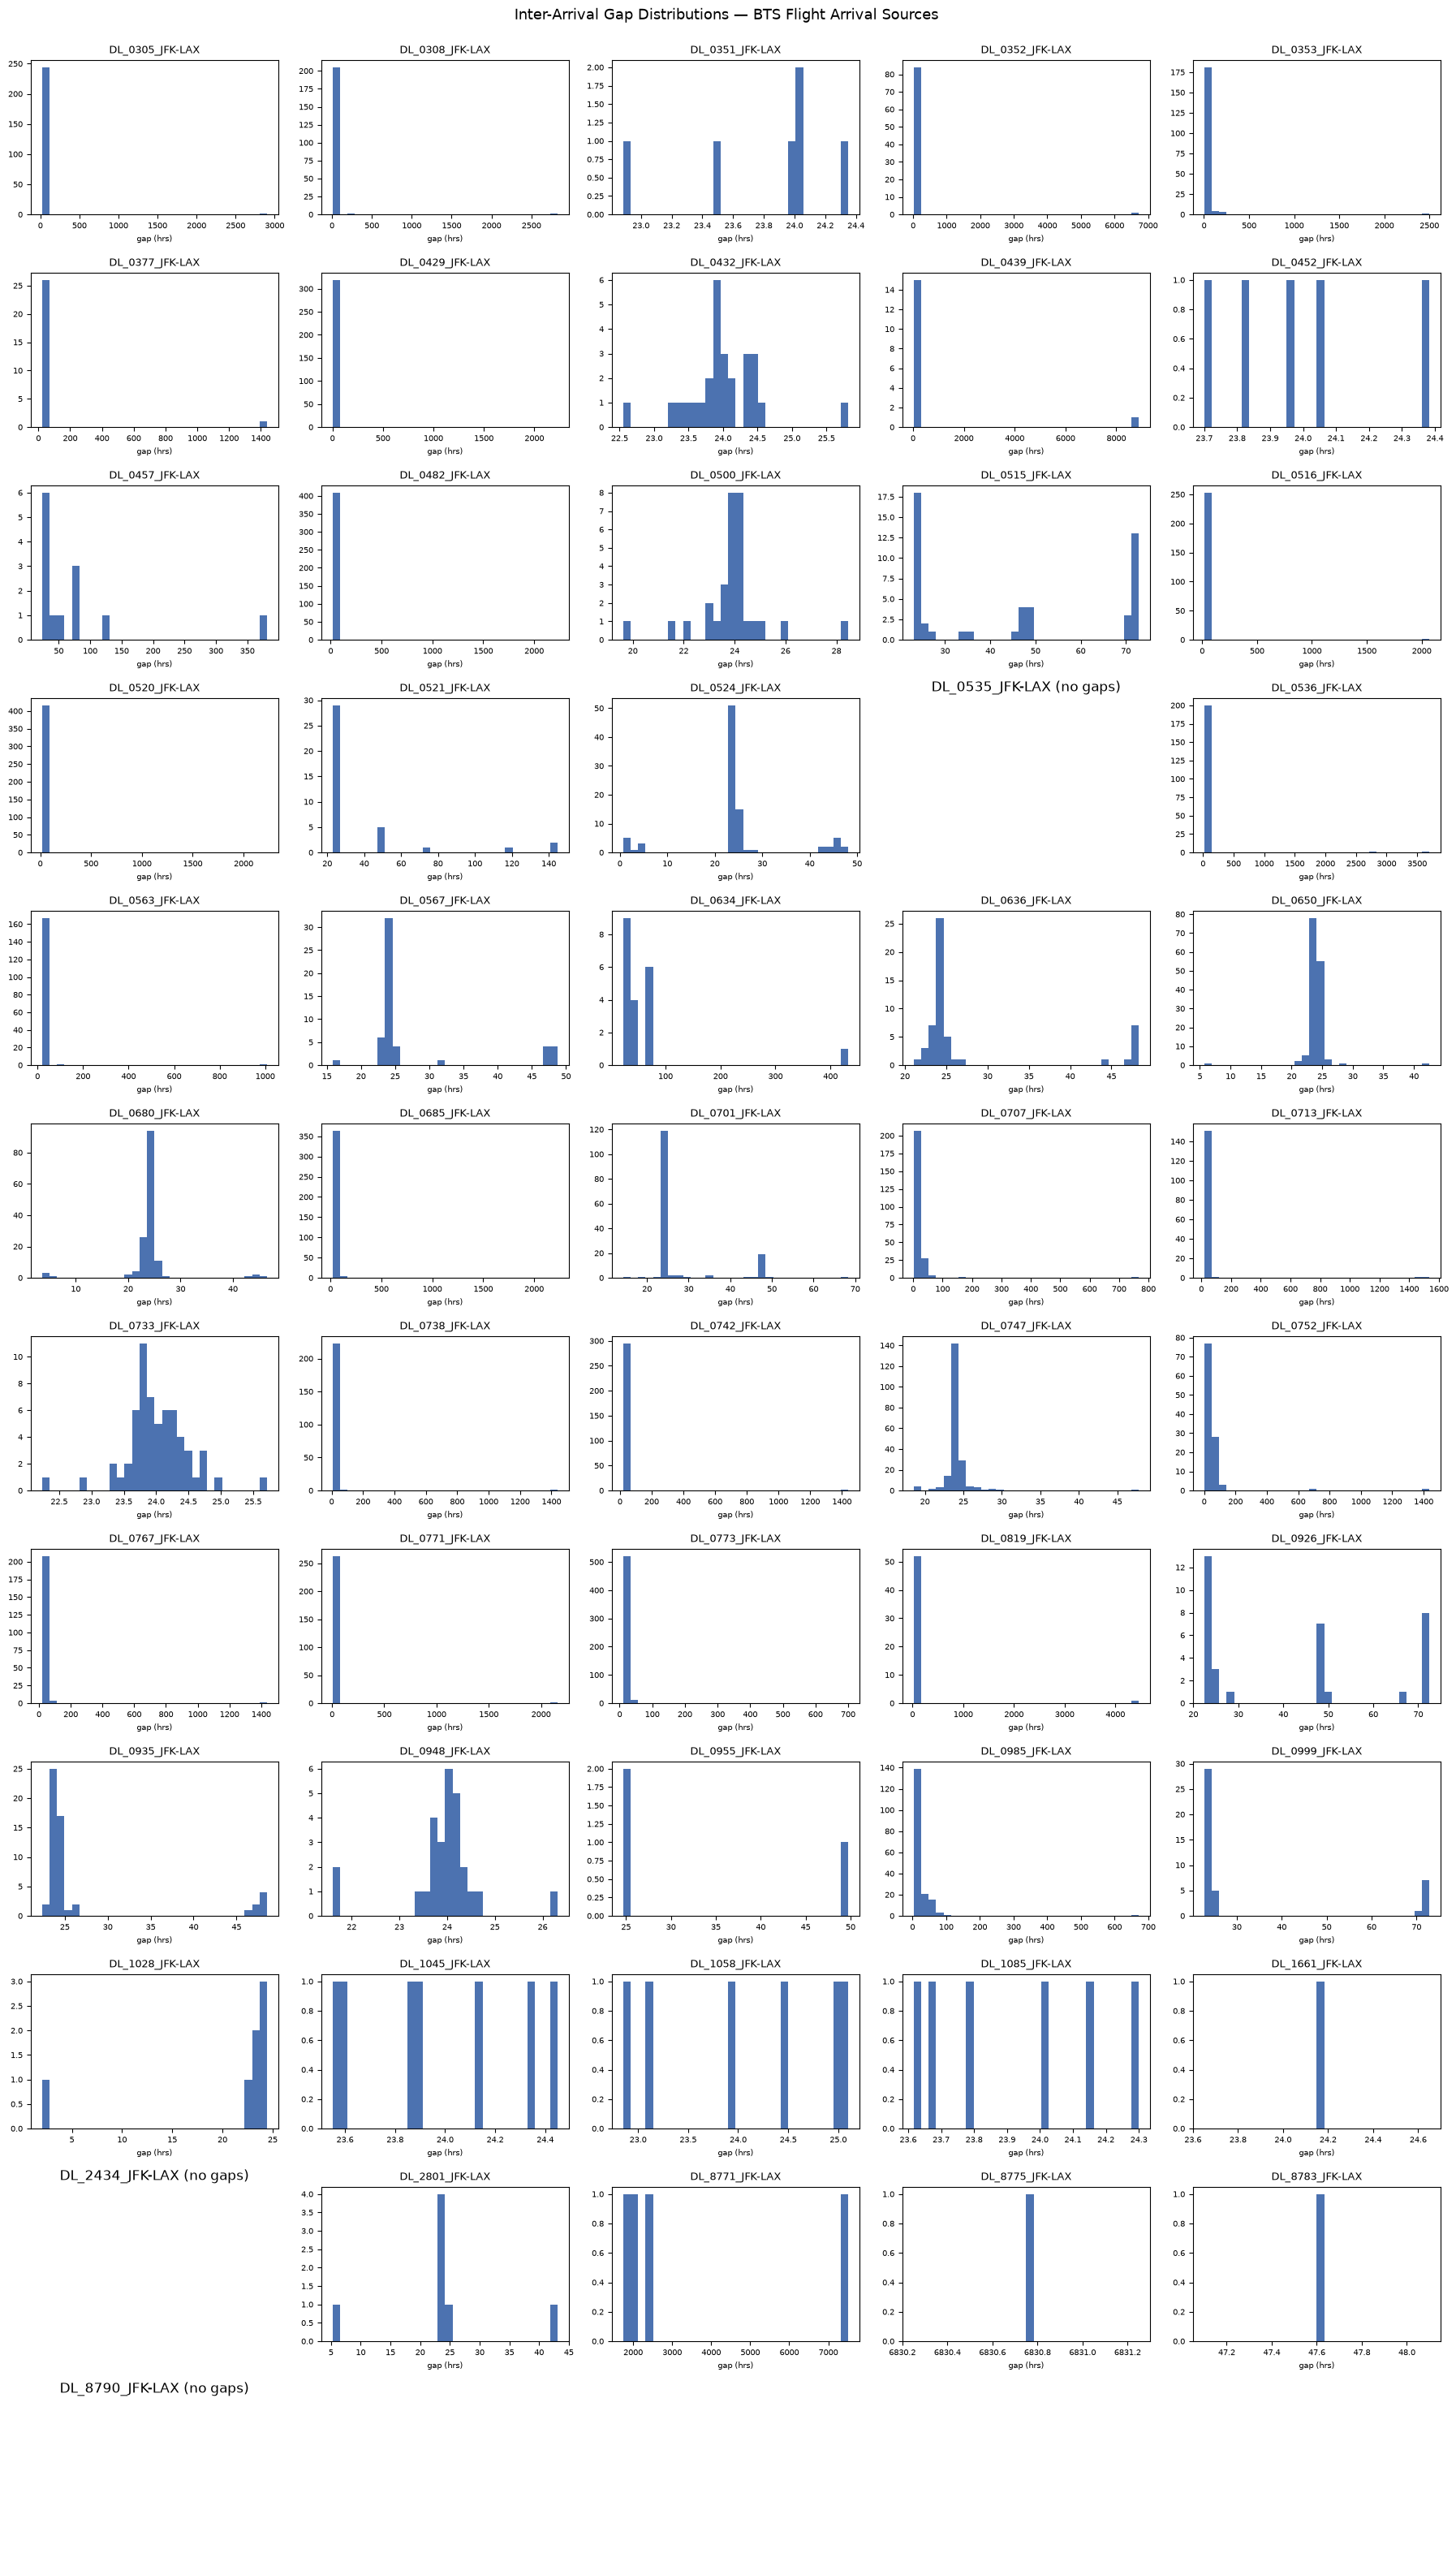

In [10]:
bts_sources = sorted(bts["source_id"].unique())
fig = plot_source_grid(bts_sources, _hist_panel, ncols=5, df=bts)
fig.suptitle("Inter-Arrival Gap Distributions — BTS Flight Arrival Sources", y=1.01, fontsize=13)
plt.show()

In [11]:
bts_summary = source_summary(bts)
bts_summary.round(4)
(
    bts_summary[display_cols]
    .style
    .format({
        "mean_hrs": "{:.2f}", "median_hrs": "{:.2f}", "std_hrs": "{:.2f}",
        "pearson_skewness": "{:.3f}", "burst_rate": "{:.2%}",
    })
    .background_gradient(subset=["pearson_skewness"], cmap="RdBu_r", vmin=-1, vmax=1)
    .background_gradient(subset=["burst_rate"], cmap="Oranges")
    .set_caption("Per-Source Summary Statistics — BTS Dataset")
)

,source_id,pattern,n_arrivals,mean_hrs,median_hrs,std_hrs,pearson_skewness,burst_rate
0,DL_0305_JFK-LAX,BTS Airline On-Time Performance — DL flight 0305 (JFK -> LAX),246,35.95,24.02,184.00,0.195,0.00%
1,DL_0308_JFK-LAX,BTS Airline On-Time Performance — DL flight 0308 (JFK -> LAX),208,49.04,24.48,195.48,0.377,0.97%
2,DL_0351_JFK-LAX,BTS Airline On-Time Performance — DL flight 0351 (JFK -> LAX),7,23.79,23.99,0.52,-1.150,0.00%
3,DL_0352_JFK-LAX,BTS Airline On-Time Performance — DL flight 0352 (JFK -> LAX),86,102.83,23.93,726.80,0.326,0.00%
4,DL_0353_JFK-LAX,BTS Airline On-Time Performance — DL flight 0353 (JFK -> LAX),190,42.95,24.12,181.64,0.311,1.59%
5,DL_0377_JFK-LAX,BTS Airline On-Time Performance — DL flight 0377 (JFK -> LAX),28,80.86,24.23,271.69,0.625,0.00%
6,DL_0429_JFK-LAX,BTS Airline On-Time Performance — DL flight 0429 (JFK -> LAX),321,31.72,24.03,123.75,0.186,8.12%
7,DL_0432_JFK-LAX,BTS Airline On-Time Performance — DL flight 0432 (JFK -> LAX),28,24.00,23.93,0.57,0.368,0.00%
8,DL_0439_JFK-LAX,BTS Airline On-Time Performance — DL flight 0439 (JFK -> LAX),17,648.71,157.98,2197.97,0.670,43.75%
9,DL_0452_JFK-LAX,BTS Airline On-Time Performance — DL flight 0452 (JFK -> LAX),6,23.99,23.97,0.26,0.232,0.00%


## 5. Missing-Data / Logging-Gap Patterns

**Synthetic data** — a "long gap" (more than `LONG_GAP_MULTIPLIER` times a
source's own median gap) is a reasonable proxy for a missed/late arrival,
including the deliberately-injected outages in `SRC_19`.

**BTS data** — since cancelled flights are already excluded, the relevant
completeness question is whether a given route/flight has missing
*calendar days* relative to its expected schedule.

In [12]:

def flag_long_gaps(df, multiplier=LONG_GAP_MULTIPLIER):
    out = []
    for source_id, g in df.groupby("source_id"):
        gaps = g["inter_arrival_hrs"]
        median = gaps.median()
        if pd.isna(median) or median == 0:
            continue
        long_mask = gaps > multiplier * median
        out.append({
            "source_id": source_id,
            "n_gaps": gaps.notna().sum(),
            "n_long_gaps": int(long_mask.sum()),
            "long_gap_rate": long_mask.mean(),
        })
    return pd.DataFrame(out).sort_values("long_gap_rate", ascending=False)

long_gap_summary = flag_long_gaps(synth)
long_gap_summary.head(10).style.format({"long_gap_rate": "{:.2%}"}).set_caption(
    "Sources with the highest rate of unusually long gaps"
)


,source_id,n_gaps,n_long_gaps,long_gap_rate
5,SRC_06,312,104,33.23%
10,SRC_11,2609,521,19.96%
9,SRC_10,1043,104,9.96%
24,SRC_25,2021,187,9.25%
21,SRC_22,569,46,8.07%
6,SRC_07,499,35,7.00%
25,SRC_26,521,23,4.41%
2,SRC_03,521,19,3.64%
1,SRC_02,730,0,0.00%
0,SRC_01,730,0,0.00%


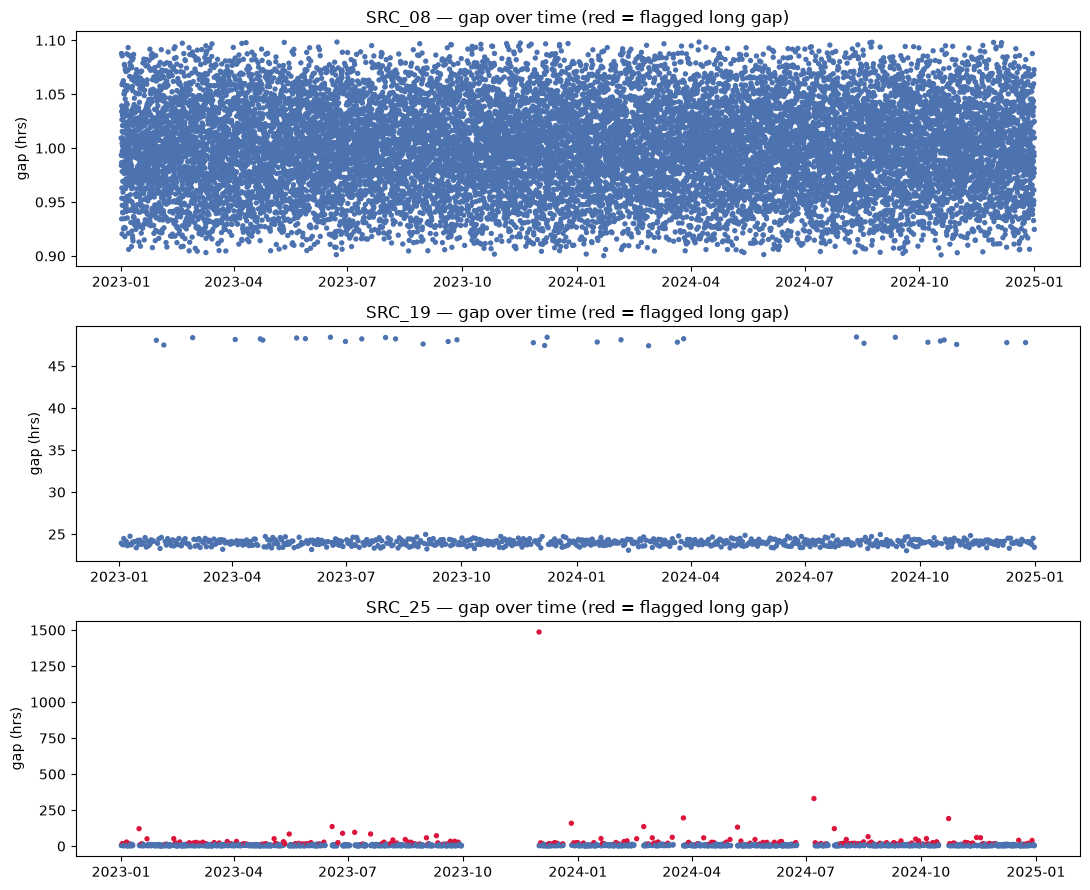

In [13]:

# Visualize gap-over-time for a few illustrative sources: an intentionally
# lossy source (SRC_19), a heavy-tailed source (SRC_25), and a dense,
# well-behaved source for contrast (SRC_08).
illustrative = ["SRC_08", "SRC_19", "SRC_25"]
fig, axes = plt.subplots(len(illustrative), 1, figsize=(11, 3 * len(illustrative)), sharex=False)
for ax, source_id in zip(np.atleast_1d(axes), illustrative):
    g = synth[synth["source_id"] == source_id].dropna(subset=["inter_arrival_hrs"])
    median = g["inter_arrival_hrs"].median()
    is_long = g["inter_arrival_hrs"] > LONG_GAP_MULTIPLIER * median
    ax.scatter(g["arrival_timestamp"], g["inter_arrival_hrs"], s=8, c=np.where(is_long, "crimson", "#4C72B0"))
    ax.set_title(f"{source_id} — gap over time (red = flagged long gap)")
    ax.set_ylabel("gap (hrs)")
fig.tight_layout()
plt.show()


In [14]:

if not bts.empty:
    completeness_rows = []
    for source_id, g in bts.groupby("source_id"):
        obs_days = g["arrival_timestamp"].dt.normalize().unique()
        full_range = pd.date_range(obs_days.min(), obs_days.max(), freq="D")
        missing_days = full_range.difference(obs_days)
        completeness_rows.append({
            "source_id": source_id,
            "expected_days": len(full_range),
            "observed_days": len(obs_days),
            "missing_days": len(missing_days),
            "completeness": len(obs_days) / len(full_range) if len(full_range) else np.nan,
        })
    bts_completeness = pd.DataFrame(completeness_rows).sort_values("completeness")
    print(bts_completeness)
else:
    print("Skipped — no BTS data loaded.")


          source_id  expected_days  observed_days  missing_days  completeness
53  DL_8775_JFK-LAX            285              2           283      0.007018
52  DL_8771_JFK-LAX            574              5           569      0.008711
8   DL_0439_JFK-LAX            434             17           417      0.039171
38  DL_0819_JFK-LAX            242             54           188      0.223140
3   DL_0352_JFK-LAX            365             86           279      0.235616
5   DL_0377_JFK-LAX             92             28            64      0.304348
10  DL_0457_JFK-LAX             42             14            28      0.333333
22  DL_0634_JFK-LAX             54             21            33      0.388889
34  DL_0752_JFK-LAX            271            111           160      0.409594
19  DL_0536_JFK-LAX            484            203           281      0.419421
1   DL_0308_JFK-LAX            424            208           216      0.490566
29  DL_0713_JFK-LAX            297            155           142 

## 6. Consolidated Summary Tables (Report-Ready)

Final formatted tables — saved to `data/analysis_outputs/` for direct
inclusion in the written report.

In [15]:

synth_summary.round(4).to_csv(ANALYSIS_OUTPUT_DIR / "synthetic_summary_stats.csv", index=False)
long_gap_summary.round(4).to_csv(ANALYSIS_OUTPUT_DIR / "synthetic_long_gap_rates.csv", index=False)
print("Saved synthetic_summary_stats.csv and synthetic_long_gap_rates.csv")

Saved synthetic_summary_stats.csv and synthetic_long_gap_rates.csv


In [16]:

if not bts.empty:
    bts_summary.round(4).to_csv(ANALYSIS_OUTPUT_DIR / "bts_summary_stats.csv", index=False)
    print("Saved bts_summary_stats.csv")
else:
    print("Skipped — no BTS data loaded.")


Saved bts_summary_stats.csv
